# 03 — Machine Learning: Predicting Business Profitability

This notebook develops regression and classification models to predict business profitability using the Superstore dataset.

The objective is to identify the factors influencing profitability, predict transaction-level profit, and classify transactions according to their risk of generating a loss.

In [40]:

# ============================================
# STEP 1: IMPORT LIBRARIES AND LOAD THE DATA
# ============================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import sklearn

from pathlib import Path

# Display settings
pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")

# Check machine learning library
print("Scikit-learn version:", sklearn.__version__)

# Locate the dataset
possible_paths = [
    Path.cwd().parent / "data" / "Superstore.xls",
    Path.cwd() / "data" / "Superstore.xls",
]

file_path = next(
    (path for path in possible_paths if path.exists()),
    None
)

if file_path is None:
    raise FileNotFoundError(
        "Superstore.xls was not found. Check the data folder."
    )

print("\nDataset found:", file_path)

# Load the three sheets
orders = pd.read_excel(file_path, sheet_name="Orders")
returns = pd.read_excel(file_path, sheet_name="Returns")
people = pd.read_excel(file_path, sheet_name="People")

# Display dataset dimensions
print("\nDATASET DIMENSIONS")
print("Orders:", orders.shape)
print("Returns:", returns.shape)
print("People:", people.shape)

# Verify required columns
print("\nORDERS COLUMNS:")
print(orders.columns.tolist())

# Display first five observations
display(orders.head())


Scikit-learn version: 1.9.1

Dataset found: c:\Users\USER\Desktop\Supersore_Profitability_Project\Data-Analysis-Git\data\Superstore.xls


C:\Users\USER\AppData\Local\Temp\ipykernel_39680\1237133930.py:40: Pandas4Warning: The xlrd engine is deprecated and will be removed in a future version. Use the calamine engine instead, by setting engine='calamine'.
  orders = pd.read_excel(file_path, sheet_name="Orders")
C:\Users\USER\AppData\Local\Temp\ipykernel_39680\1237133930.py:41: Pandas4Warning: The xlrd engine is deprecated and will be removed in a future version. Use the calamine engine instead, by setting engine='calamine'.
  returns = pd.read_excel(file_path, sheet_name="Returns")
C:\Users\USER\AppData\Local\Temp\ipykernel_39680\1237133930.py:42: Pandas4Warning: The xlrd engine is deprecated and will be removed in a future version. Use the calamine engine instead, by setting engine='calamine'.
  people = pd.read_excel(file_path, sheet_name="People")



DATASET DIMENSIONS
Orders: (10194, 21)
Returns: (800, 2)
People: (4, 2)

ORDERS COLUMNS:
['Row ID', 'Order ID', 'Order Date', 'Ship Date', 'Ship Mode', 'Customer ID', 'Customer Name', 'Segment', 'Country/Region', 'City', 'State/Province', 'Postal Code', 'Region', 'Product ID', 'Category', 'Sub-Category', 'Product Name', 'Sales', 'Quantity', 'Discount', 'Profit']


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country/Region,City,State/Province,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,US-2021-103800,2021-01-03,2021-01-07,Standard Class,DP-13000,Darren Powers,Consumer,United States,Houston,Texas,77095,Central,OFF-PA-10000174,Office Supplies,Paper,"Message Book, Wirebound, Four 5 1/2"" X 4"" Form...",16.448,2,0.200,5.551
1,2,US-2021-112326,2021-01-04,2021-01-08,Standard Class,PO-19195,Phillina Ober,Home Office,United States,Naperville,Illinois,60540,Central,OFF-BI-10004094,Office Supplies,Binders,GBC Standard Plastic Binding Systems Combs,3.540,2,0.800,-5.487
2,3,US-2021-112326,2021-01-04,2021-01-08,Standard Class,PO-19195,Phillina Ober,Home Office,United States,Naperville,Illinois,60540,Central,OFF-LA-10003223,Office Supplies,Labels,Avery 508,11.784,3,0.200,4.272
3,4,US-2021-112326,2021-01-04,2021-01-08,Standard Class,PO-19195,Phillina Ober,Home Office,United States,Naperville,Illinois,60540,Central,OFF-ST-10002743,Office Supplies,Storage,SAFCO Boltless Steel Shelving,272.736,3,0.200,-64.775
4,5,US-2021-141817,2021-01-05,2021-01-12,Standard Class,MB-18085,Mick Brown,Consumer,United States,Philadelphia,Pennsylvania,19143,East,OFF-AR-10003478,Office Supplies,Art,Avery Hi-Liter EverBold Pen Style Fluorescent ...,19.536,3,0.200,4.884


In [58]:

# ============================================
# STEP 2: DEFINE PREDICTION TARGETS
# ============================================

# Create a separate working dataset
orders_ml = orders.copy()

# Regression target
y_regression = orders_ml["Profit"].copy()

# Classification target
orders_ml["Loss_Making"] = (
    orders_ml["Profit"] < 0
).astype(int)

y_classification = orders_ml["Loss_Making"].copy()

# Examine target distributions
print("REGRESSION TARGET")
print("Target: Profit")
print(y_regression.describe())

print("\nCLASSIFICATION TARGET")
print("Target: Loss_Making")

class_counts = y_classification.value_counts().sort_index()

print("\nClass counts:")
print(class_counts.rename(index={
    0: "Not Loss-Making",
    1: "Loss-Making"
}))

print("\nClass percentages:")
print(
    (y_classification.value_counts(normalize=True)
     .sort_index() * 100).round(2)
)

# Verify target integrity
print("\nTARGET VERIFICATION")
print("Missing Profit values:", y_regression.isna().sum())
print("Missing classification values:",
      y_classification.isna().sum())

print("Break-even transactions:",
      (y_regression == 0).sum())

print("\nUnique orders:", orders_ml["Order ID"].nunique())

print("Transactions:", len(orders_ml))

print("Transactions per order (average):",
      round(
          len(orders_ml) / orders_ml["Order ID"].nunique(), 2
      ))


REGRESSION TARGET
Target: Profit
count   10,194.000
mean        28.673
std        232.465
min     -6,599.978
25%          1.761
50%          8.690
75%         29.298
max      8,399.976
Name: Profit, dtype: float64

CLASSIFICATION TARGET
Target: Loss_Making

Class counts:
Loss_Making
Not Loss-Making    8293
Loss-Making        1901
Name: count, dtype: int64

Class percentages:
Loss_Making
0   81.350
1   18.650
Name: proportion, dtype: float64

TARGET VERIFICATION
Missing Profit values: 0
Missing classification values: 0
Break-even transactions: 65

Unique orders: 5111
Transactions: 10194
Transactions per order (average): 1.99


### 2. Target Definition

Two prediction targets are established:

- **Regression target:** Profit, representing the numerical financial outcome of each transaction.
- **Classification target:** Loss_Making, a binary variable indicating whether a transaction generates a negative profit.

The classification target is defined as 1 for loss-making transactions and 0 for profitable or break-even transactions.

In [41]:

# ============================================
# STEP 2: DEFINE PREDICTION TARGETS
# ============================================

# Create a separate working dataset
orders_ml = orders.copy()

# Regression target
y_regression = orders_ml["Profit"].copy()

# Classification target
orders_ml["Loss_Making"] = (
    orders_ml["Profit"] < 0
).astype(int)

y_classification = orders_ml["Loss_Making"].copy()

# Examine target distributions
print("REGRESSION TARGET")
print("Target: Profit")
print(y_regression.describe())

print("\nCLASSIFICATION TARGET")
print("Target: Loss_Making")

class_counts = y_classification.value_counts().sort_index()

print("\nClass counts:")
print(class_counts.rename(index={
    0: "Not Loss-Making",
    1: "Loss-Making"
}))

print("\nClass percentages:")
print(
    (y_classification.value_counts(normalize=True)
     .sort_index() * 100).round(2)
)

# Verify target integrity
print("\nTARGET VERIFICATION")
print("Missing Profit values:", y_regression.isna().sum())
print("Missing classification values:",
      y_classification.isna().sum())

print("Break-even transactions:",
      (y_regression == 0).sum())

print("\nUnique orders:", orders_ml["Order ID"].nunique())

print("Transactions:", len(orders_ml))

print("Transactions per order (average):",
      round(
          len(orders_ml) / orders_ml["Order ID"].nunique(), 2
      ))


REGRESSION TARGET
Target: Profit
count   10,194.000
mean        28.673
std        232.465
min     -6,599.978
25%          1.761
50%          8.690
75%         29.298
max      8,399.976
Name: Profit, dtype: float64

CLASSIFICATION TARGET
Target: Loss_Making

Class counts:
Loss_Making
Not Loss-Making    8293
Loss-Making        1901
Name: count, dtype: int64

Class percentages:
Loss_Making
0   81.350
1   18.650
Name: proportion, dtype: float64

TARGET VERIFICATION
Missing Profit values: 0
Missing classification values: 0
Break-even transactions: 65

Unique orders: 5111
Transactions: 10194
Transactions per order (average): 1.99


### 3. Feature Engineering and Selection

This stage identifies the explanatory variables that can be used to predict transaction profitability.

The selection process considers business relevance, predictive value, data quality, and potential data leakage.

Variables that reveal the actual financial outcome or information only available after the transaction will be excluded.

In [42]:

# ============================================
# STEP 3: FEATURE INVESTIGATION
# ============================================

# 1. Inspect data types
display(orders_ml.dtypes.to_frame("Data Type"))
display(orders_ml.dtypes.to_frame("Data Type"))

# 2. Inspect unique values
print("\nUNIQUE VALUES PER COLUMN")

unique_counts = pd.DataFrame({
    "Column": orders_ml.columns,
    "Unique_Values": [
        orders_ml[col].nunique()
        for col in orders_ml.columns
    ]
})

display(
    unique_counts.sort_values(
        "Unique_Values",
        ascending=False
    )
)

# 3. Inspect date ranges
print("\nDATE INFORMATION")

orders_ml["Order Date"] = pd.to_datetime(
    orders_ml["Order Date"]
)

orders_ml["Ship Date"] = pd.to_datetime(
    orders_ml["Ship Date"]
)

print("First order:", orders_ml["Order Date"].min())
print("Last order:", orders_ml["Order Date"].max())

# 4. Check geographical information
print("\nGEOGRAPHICAL INFORMATION")

for col in ["Region", "State/Province", "City"]:
    print(f"\n{col}:")
    print("Unique values:", orders_ml[col].nunique())

# 5. Check product information
print("\nPRODUCT INFORMATION")

for col in ["Product ID", "Product Name",
            "Category", "Sub-Category"]:
    print(f"{col}: {orders_ml[col].nunique()} unique values")

# 6. Check whether orders contain multiple transactions
print("\nORDER STRUCTURE")

print("Total transactions:", len(orders_ml))
print("Unique orders:", orders_ml["Order ID"].nunique())

print(
    "Orders with multiple product lines:",
    (orders_ml.groupby("Order ID").size() > 1).sum()
)

# 7. Verify target distribution
print("\nTARGET DISTRIBUTION")

print(
    "Loss-making:",
    (orders_ml["Profit"] < 0).sum()
)

print(
    "Break-even:",
    (orders_ml["Profit"] == 0).sum()
)

print(
    "Profitable:",
    (orders_ml["Profit"] > 0).sum()
)


,Data Type
Row ID,int64
Order ID,str
Order Date,datetime64[us]
Ship Date,datetime64[us]
Ship Mode,str
Customer ID,str
Customer Name,str
Segment,str
Country/Region,str
City,str


,Data Type
Row ID,int64
Order ID,str
Order Date,datetime64[us]
Ship Date,datetime64[us]
Ship Mode,str
Customer ID,str
Customer Name,str
Segment,str
Country/Region,str
City,str



UNIQUE VALUES PER COLUMN


,Column,Unique_Values
0,Row ID,10194
20,Profit,7597
17,Sales,6161
1,Order ID,5111
13,Product ID,1862
16,Product Name,1849
3,Ship Date,1338
2,Order Date,1242
5,Customer ID,804
6,Customer Name,800



DATE INFORMATION
First order: 2021-01-03 00:00:00
Last order: 2024-12-30 00:00:00

GEOGRAPHICAL INFORMATION

Region:
Unique values: 4

State/Province:
Unique values: 59

City:
Unique values: 542

PRODUCT INFORMATION
Product ID: 1862 unique values
Product Name: 1849 unique values
Category: 3 unique values
Sub-Category: 17 unique values

ORDER STRUCTURE
Total transactions: 10194
Unique orders: 5111
Orders with multiple product lines: 2518

TARGET DISTRIBUTION
Loss-making: 1901
Break-even: 65
Profitable: 8228


### 4. Feature Engineering

This stage transforms the original transaction data into useful predictive features.

Date variables will be extracted from Order Date to identify potential seasonal and temporal patterns in business profitability.

Identifiers and variables that reveal the actual financial outcome will not be used as predictive inputs.

In [43]:

# ============================================
# STEP 4: FEATURE ENGINEERING
# ============================================

# Create a working copy
orders_ml = orders.copy()

# Convert Order Date
orders_ml["Order Date"] = pd.to_datetime(
    orders_ml["Order Date"]
)

# Extract date features
orders_ml["Order_Year"] = orders_ml["Order Date"].dt.year

orders_ml["Order_Month"] = orders_ml["Order Date"].dt.month

orders_ml["Order_Quarter"] = orders_ml["Order Date"].dt.quarter

orders_ml["Order_DayOfWeek"] = orders_ml["Order Date"].dt.dayofweek

orders_ml["Order_Weekend"] = (
    orders_ml["Order_DayOfWeek"] >= 5
).astype(int)

# Create prediction targets
orders_ml["Loss_Making"] = (
    orders_ml["Profit"] < 0
).astype(int)

# Display engineered features
print("NEW FEATURES CREATED")

new_features = [
    "Order_Year",
    "Order_Month",
    "Order_Quarter",
    "Order_DayOfWeek",
    "Order_Weekend"
]

display(orders_ml[new_features].head(10))

print("\nFEATURE VERIFICATION")

print(orders_ml[new_features].isnull().sum())

print("\nYear distribution:")
print(orders_ml["Order_Year"].value_counts().sort_index())

print("\nMonth distribution:")
print(orders_ml["Order_Month"].value_counts().sort_index())


NEW FEATURES CREATED


C:\Users\USER\AppData\Local\Temp\ipykernel_39680\806008085.py:20: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  orders_ml["Order_DayOfWeek"] = orders_ml["Order Date"].dt.dayofweek


,Order_Year,Order_Month,Order_Quarter,Order_DayOfWeek,Order_Weekend
0,2021,1,1,6,1
1,2021,1,1,0,0
2,2021,1,1,0,0
3,2021,1,1,0,0
4,2021,1,1,1,0
5,2021,1,1,2,0
6,2021,1,1,2,0
7,2021,1,1,2,0
8,2021,1,1,2,0
9,2021,1,1,2,0



FEATURE VERIFICATION
Order_Year         0
Order_Month        0
Order_Quarter      0
Order_DayOfWeek    0
Order_Weekend      0
dtype: int64

Year distribution:
Order_Year
2021    2051
2022    2130
2023    2634
2024    3379
Name: count, dtype: int64

Month distribution:
Order_Month
1      404
2      300
3      711
4      670
5      758
6      725
7      718
8      722
9     1399
10     843
11    1474
12    1470
Name: count, dtype: int64


### 5. Final Feature Selection

The predictive variables are selected based on business relevance and availability at the time of prediction.

Date features are transformed to capture temporal patterns while reducing redundant information.

Identifiers and actual financial outcomes are excluded from the predictor variables to prevent data leakage.

In [44]:

# ============================================
# STEP 5: FINAL FEATURE ENGINEERING
# ============================================

# Create cyclical month features
orders_ml["Month_Sin"] = np.sin(
    2 * np.pi * orders_ml["Order_Month"] / 12
)

orders_ml["Month_Cos"] = np.cos(
    2 * np.pi * orders_ml["Order_Month"] / 12
)

# Create cyclical day-of-week features
orders_ml["Weekday_Sin"] = np.sin(
    2 * np.pi * orders_ml["Order_DayOfWeek"] / 7
)

orders_ml["Weekday_Cos"] = np.cos(
    2 * np.pi * orders_ml["Order_DayOfWeek"] / 7
)

# Final predictor list
numerical_features = [
    "Sales",
    "Quantity",
    "Discount",
    "Order_Year",
    "Month_Sin",
    "Month_Cos",
    "Weekday_Sin",
    "Weekday_Cos"
]

categorical_features = [
    "Category",
    "Sub-Category",
    "Region",
    "State/Province",
    "Segment",
    "Ship Mode"
]

features = numerical_features + categorical_features

# Define X and both targets
X = orders_ml[features].copy()

y_regression = orders_ml["Profit"].copy()

y_classification = (
    orders_ml["Profit"] < 0
).astype(int)

# Display final feature information
print("FINAL FEATURE SELECTION")

print("\nNumerical features:", len(numerical_features))
print(numerical_features)

print("\nCategorical features:", len(categorical_features))
print(categorical_features)

print("\nTotal predictors:", len(features))

print("\nPredictor dataset dimensions:", X.shape)

print("\nMissing predictor values:")
print(X.isna().sum().sum())

print("\nTarget dimensions:")
print("Regression:", y_regression.shape)
print("Classification:", y_classification.shape)

print("\nTarget leakage verification:")
print("Profit in predictors:", "Profit" in X.columns)
print("Loss_Making in predictors:", "Loss_Making" in X.columns)
print("Order ID in predictors:", "Order ID" in X.columns)

display(X.head())


FINAL FEATURE SELECTION

Numerical features: 8
['Sales', 'Quantity', 'Discount', 'Order_Year', 'Month_Sin', 'Month_Cos', 'Weekday_Sin', 'Weekday_Cos']

Categorical features: 6
['Category', 'Sub-Category', 'Region', 'State/Province', 'Segment', 'Ship Mode']

Total predictors: 14

Predictor dataset dimensions: (10194, 14)

Missing predictor values:
0

Target dimensions:
Regression: (10194,)
Classification: (10194,)

Target leakage verification:
Profit in predictors: False
Loss_Making in predictors: False
Order ID in predictors: False


,Sales,Quantity,Discount,Order_Year,Month_Sin,Month_Cos,Weekday_Sin,Weekday_Cos,Category,Sub-Category,Region,State/Province,Segment,Ship Mode
0,16.448,2,0.200,2021,0.500,0.866,-0.782,0.623,Office Supplies,Paper,Central,Texas,Consumer,Standard Class
1,3.540,2,0.800,2021,0.500,0.866,0.000,1.000,Office Supplies,Binders,Central,Illinois,Home Office,Standard Class
2,11.784,3,0.200,2021,0.500,0.866,0.000,1.000,Office Supplies,Labels,Central,Illinois,Home Office,Standard Class
3,272.736,3,0.200,2021,0.500,0.866,0.000,1.000,Office Supplies,Storage,Central,Illinois,Home Office,Standard Class
4,19.536,3,0.200,2021,0.500,0.866,0.782,0.623,Office Supplies,Art,East,Pennsylvania,Consumer,Standard Class


### 6. Training and Testing Data Split

A chronological split is used to evaluate the models on future transactions.

Transactions from 2021–2023 are used for training, while transactions from 2024 are reserved for testing.

All product lines belonging to the same Order ID are assigned to the same dataset to prevent order-level data leakage.

In [45]:

# ============================================
# STEP 6A: FINALIZE PREDICTOR VARIABLES
# ============================================

# Remove State/Province because Region is retained
categorical_features = [
    "Category",
    "Sub-Category",
    "Region",
    "Segment",
    "Ship Mode"
]

features = numerical_features + categorical_features

X = orders_ml[features].copy()

y_regression = orders_ml["Profit"].copy()

y_classification = (
    orders_ml["Profit"] < 0
).astype(int)

print("Final predictor count:", len(features))
print("Predictor dimensions:", X.shape)
print("Features:", features)


Final predictor count: 13
Predictor dimensions: (10194, 13)
Features: ['Sales', 'Quantity', 'Discount', 'Order_Year', 'Month_Sin', 'Month_Cos', 'Weekday_Sin', 'Weekday_Cos', 'Category', 'Sub-Category', 'Region', 'Segment', 'Ship Mode']


In [46]:

# ============================================
# STEP 6B: CHRONOLOGICAL TRAIN/TEST SPLIT
# ============================================

# Define the cutoff
cutoff_date = pd.Timestamp("2024-01-01")

# Identify training and testing observations
train_mask = orders_ml["Order Date"] < cutoff_date
test_mask = orders_ml["Order Date"] >= cutoff_date

# Create training and testing datasets
X_train = X.loc[train_mask].copy()
X_test = X.loc[test_mask].copy()

y_reg_train = y_regression.loc[train_mask].copy()
y_reg_test = y_regression.loc[test_mask].copy()

y_clf_train = y_classification.loc[train_mask].copy()
y_clf_test = y_classification.loc[test_mask].copy()

# Preserve Order IDs for leakage verification only
train_order_ids = set(orders_ml.loc[train_mask, "Order ID"])
test_order_ids = set(orders_ml.loc[test_mask, "Order ID"])

# Display split results
print("TRAINING DATA")
print("Observations:", len(X_train))
print("Unique orders:", len(train_order_ids))
print("Date range:",
      orders_ml.loc[train_mask, "Order Date"].min(),
      "to",
      orders_ml.loc[train_mask, "Order Date"].max())

print("\nTESTING DATA")
print("Observations:", len(X_test))
print("Unique orders:", len(test_order_ids))
print("Date range:",
      orders_ml.loc[test_mask, "Order Date"].min(),
      "to",
      orders_ml.loc[test_mask, "Order Date"].max())

# Verify no order appears in both datasets
overlap = train_order_ids.intersection(test_order_ids)

print("\nLEAKAGE VERIFICATION")
print("Orders appearing in both datasets:", len(overlap))

print("\nTARGET DISTRIBUTION")

print("\nTraining loss rate:")
print(round(y_clf_train.mean() * 100, 2), "%")

print("\nTesting loss rate:")
print(round(y_clf_test.mean() * 100, 2), "%")

# Final checks
assert len(overlap) == 0
assert len(X_train) + len(X_test) == len(X)
assert X_train.index.equals(y_reg_train.index)
assert X_test.index.equals(y_reg_test.index)

print("\nAll split verification checks passed!")


TRAINING DATA
Observations: 6815
Unique orders: 3388
Date range: 2021-01-03 00:00:00 to 2023-12-31 00:00:00

TESTING DATA
Observations: 3379
Unique orders: 1723
Date range: 2024-01-01 00:00:00 to 2024-12-30 00:00:00

LEAKAGE VERIFICATION
Orders appearing in both datasets: 0

TARGET DISTRIBUTION

Training loss rate:
18.62 %

Testing loss rate:
18.7 %

All split verification checks passed!


### 7. Data Preprocessing

This stage prepares numerical and categorical predictors for machine learning.

Numerical variables are standardized for Linear Regression, while categorical variables are converted using One-Hot Encoding.

Separate preprocessing pipelines are created for Linear Regression and Random Forest Regressor to ensure that each algorithm receives appropriately prepared data.

All preprocessing transformations are fitted using training data only to prevent data leakage.

In [47]:

# ============================================
# STEP 7A: IMPORT PREPROCESSING TOOLS
# ============================================

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline

from sklearn.impute import SimpleImputer

from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

print("Preprocessing and regression tools imported successfully.")


Preprocessing and regression tools imported successfully.


In [48]:

# ============================================
# STEP 7B: LINEAR REGRESSION PREPROCESSOR
# ============================================

numerical_transformer_linear = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer_linear = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(
        handle_unknown="ignore",
        drop="first"
    ))
])

preprocessor_linear = ColumnTransformer(
    transformers=[
        ("numerical", numerical_transformer_linear,
         numerical_features),
        ("categorical", categorical_transformer_linear,
         categorical_features)
    ]
)

print("Linear Regression preprocessor created successfully.")


Linear Regression preprocessor created successfully.


In [49]:

# ============================================
# STEP 7C: RANDOM FOREST PREPROCESSOR
# ============================================

numerical_transformer_rf = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median"))
])

categorical_transformer_rf = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(
        handle_unknown="ignore"
    ))
])

preprocessor_rf = ColumnTransformer(
    transformers=[
        ("numerical", numerical_transformer_rf,
         numerical_features),
        ("categorical", categorical_transformer_rf,
         categorical_features)
    ]
)

print("Random Forest preprocessor created successfully.")


Random Forest preprocessor created successfully.


In [50]:

# ============================================
# STEP 7D: VERIFY PREPROCESSING
# ============================================

# Fit transformations on training data only
X_train_linear_processed = preprocessor_linear.fit_transform(X_train)
X_test_linear_processed = preprocessor_linear.transform(X_test)

X_train_rf_processed = preprocessor_rf.fit_transform(X_train)
X_test_rf_processed = preprocessor_rf.transform(X_test)

print("LINEAR REGRESSION")
print("Training shape:", X_train_linear_processed.shape)
print("Testing shape:", X_test_linear_processed.shape)

print("\nRANDOM FOREST")
print("Training shape:", X_train_rf_processed.shape)
print("Testing shape:", X_test_rf_processed.shape)

print("\nPREPROCESSING VERIFICATION")

print("Linear Regression training observations:",
      X_train_linear_processed.shape[0])

print("Random Forest training observations:",
      X_train_rf_processed.shape[0])

print("\nAll preprocessing transformations completed.")


LINEAR REGRESSION
Training shape: (6815, 34)
Testing shape: (3379, 34)

RANDOM FOREST
Training shape: (6815, 39)
Testing shape: (3379, 39)

PREPROCESSING VERIFICATION
Linear Regression training observations: 6815
Random Forest training observations: 6815

All preprocessing transformations completed.


### 8. Regression Modeling

Two regression algorithms are implemented to predict transaction-level profit:

1. Linear Regression: baseline model.
2. Random Forest Regressor: nonlinear ensemble model.

Both models use the same training and testing datasets and are evaluated using MAE, RMSE, and R².

In [51]:

# ============================================
# STEP 8A: LINEAR REGRESSION
# ============================================

# Create the complete pipeline
linear_regression_model = Pipeline(steps=[
    ("preprocessor", preprocessor_linear),
    ("model", LinearRegression())
])

# Train the model
linear_regression_model.fit(
    X_train,
    y_reg_train
)

# Generate predictions
linear_predictions = linear_regression_model.predict(X_test)

print("Linear Regression trained successfully!")

print("Number of predictions:", len(linear_predictions))
print("First 10 predictions:")
print(np.round(linear_predictions[:10], 2))


Linear Regression trained successfully!
Number of predictions: 3379
First 10 predictions:
[ -13.03   99.4   -90.47  -10.25 -158.76  -11.66 -104.53 -123.09  132.49
   36.23]


In [52]:

# ============================================
# STEP 8B: RANDOM FOREST REGRESSOR
# ============================================

# Create the model
random_forest_model = Pipeline(steps=[
    ("preprocessor", preprocessor_rf),
    ("model", RandomForestRegressor(
        n_estimators=300,
        random_state=42,
        n_jobs=-1
    ))
])

# Train the model
random_forest_model.fit(
    X_train,
    y_reg_train
)

# Generate predictions
rf_predictions = random_forest_model.predict(X_test)

print("Random Forest Regressor trained successfully!")

print("Number of predictions:", len(rf_predictions))
print("First 10 predictions:")
print(np.round(rf_predictions[:10], 2))


Random Forest Regressor trained successfully!
Number of predictions: 3379
First 10 predictions:
[ -61.31  128.12 -144.19    8.5   -30.18    1.79  -10.61  -21.92    1.38
  -71.22]


In [53]:

# ============================================
# STEP 8C: REGRESSION MODEL EVALUATION
# ============================================

def evaluate_regression(y_true, y_pred, model_name):

    mae = mean_absolute_error(y_true, y_pred)

    rmse = np.sqrt(
        mean_squared_error(y_true, y_pred)
    )

    r2 = r2_score(y_true, y_pred)

    return {
        "Model": model_name,
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2
    }


# Evaluate both models
regression_results = pd.DataFrame([
    evaluate_regression(
        y_reg_test,
        linear_predictions,
        "Linear Regression"
    ),

    evaluate_regression(
        y_reg_test,
        rf_predictions,
        "Random Forest Regressor"
    )
])

print("REGRESSION MODEL COMPARISON")
display(regression_results.round(4))


REGRESSION MODEL COMPARISON


,Model,MAE,RMSE,R2
0,Linear Regression,58.529,188.602,0.386
1,Random Forest Regressor,18.654,106.379,0.804


### 9. Regression Error Analysis

This section examines the accuracy of the regression models by comparing actual and predicted profit values.

The analysis includes actual-versus-predicted plots, residual distributions, and identification of transactions with the largest prediction errors.

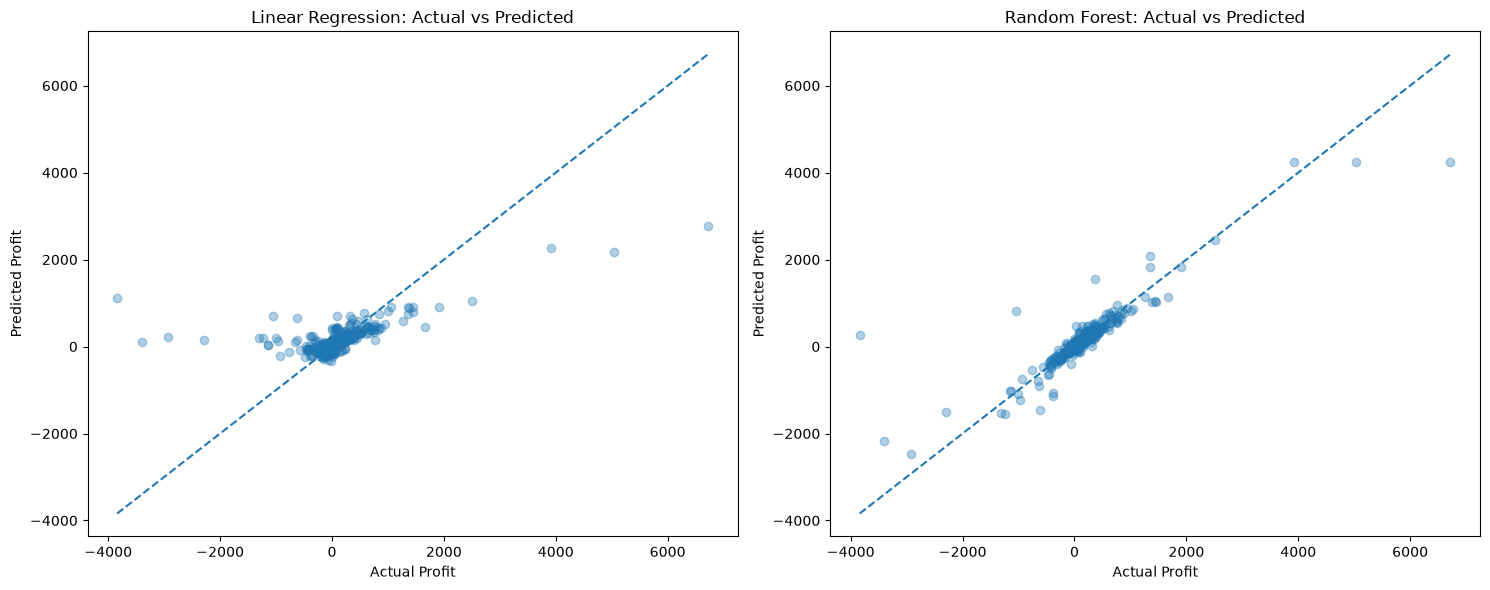

In [54]:

# ============================================
# STEP 9A: ACTUAL VS PREDICTED PROFIT
# ============================================

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

models_predictions = [
    ("Linear Regression", linear_predictions),
    ("Random Forest", rf_predictions)
]

for ax, (name, predictions) in zip(axes, models_predictions):

    ax.scatter(
        y_reg_test,
        predictions,
        alpha=0.35
    )

    minimum = min(y_reg_test.min(), predictions.min())
    maximum = max(y_reg_test.max(), predictions.max())

    ax.plot(
        [minimum, maximum],
        [minimum, maximum],
        linestyle="--"
    )

    ax.set_title(f"{name}: Actual vs Predicted")
    ax.set_xlabel("Actual Profit")
    ax.set_ylabel("Predicted Profit")

plt.tight_layout()
plt.show()


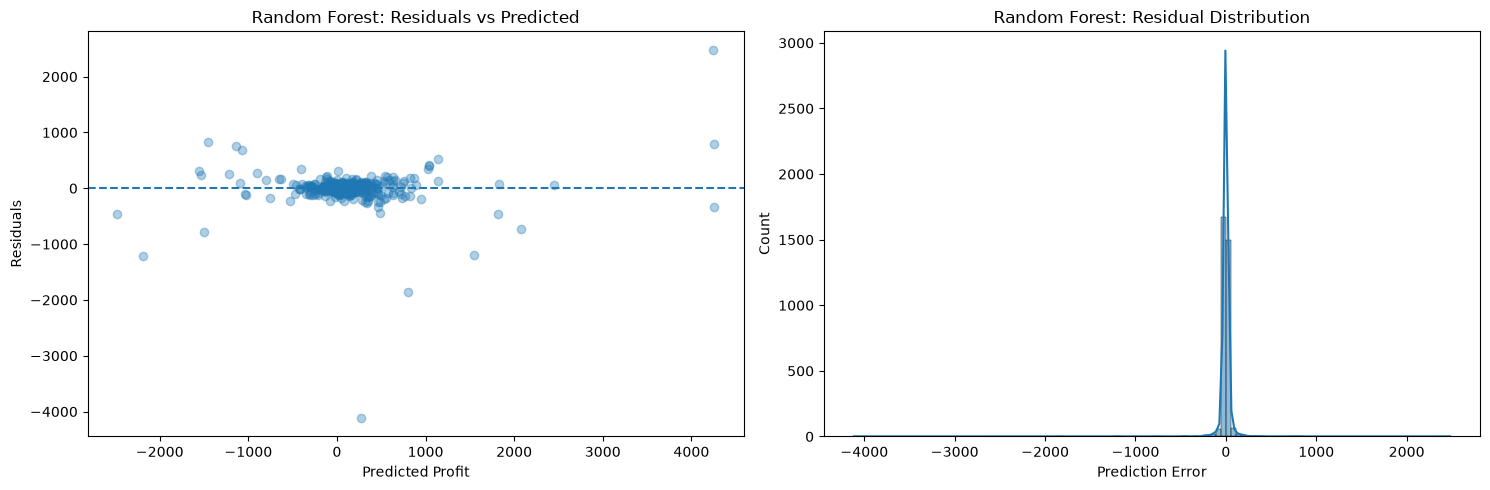

RESIDUAL STATISTICS
count    3,379.000
mean        -0.666
std        106.392
min     -4,116.744
25%         -1.408
50%          0.061
75%          2.161
max      2,481.507
Name: Profit, dtype: float64

Mean residual: -0.666
Median absolute error: 1.804


In [55]:

# ============================================
# STEP 9B: RANDOM FOREST RESIDUAL ANALYSIS
# ============================================

rf_residuals = y_reg_test - rf_predictions

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Residuals vs predicted
axes[0].scatter(
    rf_predictions,
    rf_residuals,
    alpha=0.35
)

axes[0].axhline(0, linestyle="--")
axes[0].set_title("Random Forest: Residuals vs Predicted")
axes[0].set_xlabel("Predicted Profit")
axes[0].set_ylabel("Residuals")

# Residual distribution
sns.histplot(
    rf_residuals,
    kde=True,
    ax=axes[1]
)

axes[1].set_title("Random Forest: Residual Distribution")
axes[1].set_xlabel("Prediction Error")

plt.tight_layout()
plt.show()

print("RESIDUAL STATISTICS")
print(rf_residuals.describe())

print("\nMean residual:", round(rf_residuals.mean(), 3))
print("Median absolute error:", round(rf_residuals.abs().median(), 3))


In [56]:

# ============================================
# STEP 9C: BASELINE COMPARISON
# ============================================

from sklearn.dummy import DummyRegressor

baseline_model = DummyRegressor(strategy="mean")

baseline_model.fit(
    X_train,
    y_reg_train
)

baseline_predictions = baseline_model.predict(X_test)

baseline_results = evaluate_regression(
    y_reg_test,
    baseline_predictions,
    "Mean Baseline"
)

comparison = pd.DataFrame([
    baseline_results,
    evaluate_regression(
        y_reg_test,
        linear_predictions,
        "Linear Regression"
    ),
    evaluate_regression(
        y_reg_test,
        rf_predictions,
        "Random Forest Regressor"
    )
])

print("BASELINE AND MODEL COMPARISON")
display(comparison.round(4))


BASELINE AND MODEL COMPARISON


,Model,MAE,RMSE,R2
0,Mean Baseline,64.392,240.587,-0.000
1,Linear Regression,58.529,188.602,0.386
2,Random Forest Regressor,18.654,106.379,0.804


### 10. Feature Importance Analysis

This section investigates which business variables contribute most to the Random Forest model's predictions.

Permutation importance is used to measure how much model performance deteriorates when an individual predictor is randomly shuffled.

This helps identify the variables that are most informative for predicting transaction profitability.

RANDOM FOREST FEATURE IMPORTANCE


,Feature,Importance,Std
0,Sales,90.072,0.776
2,Discount,51.728,0.298
9,Sub-Category,13.382,0.291
8,Category,6.505,0.068
1,Quantity,3.361,0.057
10,Region,1.641,0.150
4,Month_Sin,1.422,0.026
5,Month_Cos,1.347,0.055
6,Weekday_Sin,1.229,0.032
12,Ship Mode,0.861,0.026


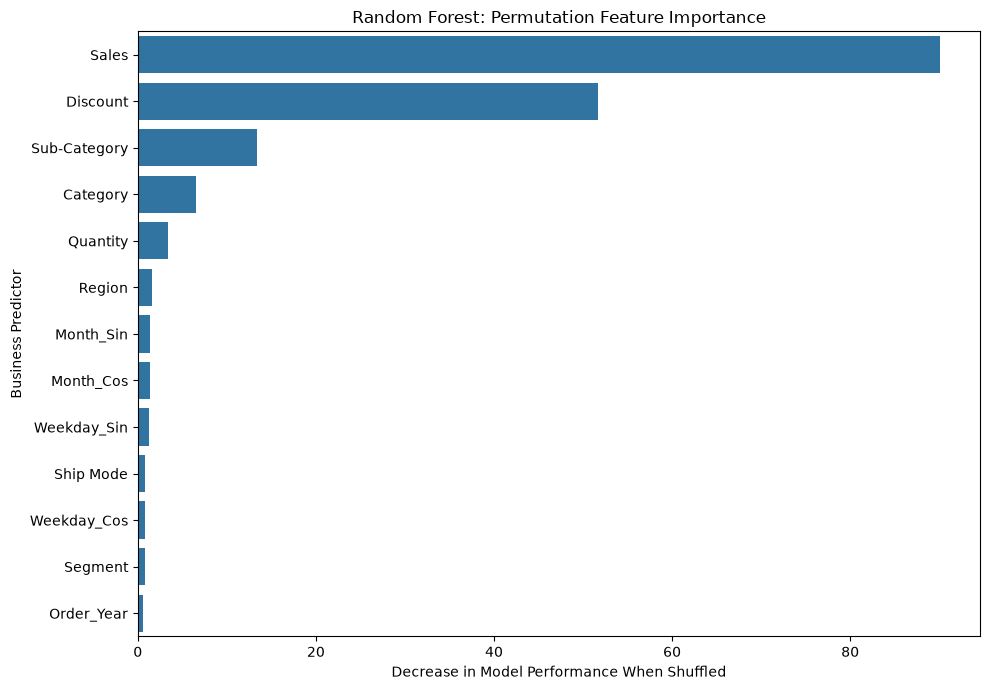

In [57]:

# ============================================
# STEP 10: PERMUTATION FEATURE IMPORTANCE
# ============================================

from sklearn.inspection import permutation_importance

# Calculate importance using training data
importance_result = permutation_importance(
    random_forest_model,
    X_train,
    y_reg_train,
    n_repeats=5,
    random_state=42,
    scoring="neg_mean_absolute_error",
    n_jobs=-1
)

# Create importance table
feature_importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": importance_result.importances_mean,
    "Std": importance_result.importances_std
})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

print("RANDOM FOREST FEATURE IMPORTANCE")
display(feature_importance.round(4))

# Visualize the 13 predictors
plt.figure(figsize=(10, 7))

sns.barplot(
    data=feature_importance,
    x="Importance",
    y="Feature"
)

plt.title("Random Forest: Permutation Feature Importance")
plt.xlabel("Decrease in Model Performance When Shuffled")
plt.ylabel("Business Predictor")
plt.tight_layout()
plt.show()


### 11. Regression Cross-Validation

Cross-validation is conducted to assess the stability and generalization performance of the regression models.

TimeSeriesSplit is used because the dataset contains chronological observations. Each validation fold follows its corresponding training period, preventing future observations from being used to predict the past.

The analysis evaluates Linear Regression and Random Forest Regressor using MAE, RMSE and R².

In [59]:

# ============================================
# STEP 11A: CROSS-VALIDATION IMPORTS
# ============================================

from sklearn.model_selection import TimeSeriesSplit, cross_validate

print("Time-series cross-validation tools imported.")


Time-series cross-validation tools imported.


In [60]:

# ============================================
# STEP 11B: VERIFY CHRONOLOGICAL ORDER
# ============================================

print("Training date range:")
print(X_train.index.min(), "to", X_train.index.max())

print("\nChecking chronological order:")

print(
    "Training observations are chronologically ordered:",
    orders_ml.loc[X_train.index, "Order Date"].is_monotonic_increasing
)


Training date range:
0 to 6814

Checking chronological order:
Training observations are chronologically ordered: True


In [61]:

# ============================================
# STEP 11C: TIME SERIES CROSS-VALIDATION
# ============================================

tscv = TimeSeriesSplit(n_splits=5)

for fold, (train_idx, val_idx) in enumerate(
    tscv.split(X_train), start=1
):
    print(f"\nFOLD {fold}")
    print("Training observations:", len(train_idx))
    print("Validation observations:", len(val_idx))

print("\nFive chronological folds created.")



FOLD 1
Training observations: 1140
Validation observations: 1135

FOLD 2
Training observations: 2275
Validation observations: 1135

FOLD 3
Training observations: 3410
Validation observations: 1135

FOLD 4
Training observations: 4545
Validation observations: 1135

FOLD 5
Training observations: 5680
Validation observations: 1135

Five chronological folds created.


In [62]:

# ============================================
# STEP 11D: CROSS-VALIDATION RESULTS
# ============================================

scoring = {
    "MAE": "neg_mean_absolute_error",
    "RMSE": "neg_root_mean_squared_error",
    "R2": "r2"
}

models = {
    "Linear Regression": linear_regression_model,
    "Random Forest": random_forest_model
}

cv_results = []

for model_name, model in models.items():

    print(f"\nEvaluating {model_name}...")

    scores = cross_validate(
        model,
        X_train,
        y_reg_train,
        cv=tscv,
        scoring=scoring,
        n_jobs=-1
    )

    cv_results.append({
        "Model": model_name,
        "Mean MAE": -scores["test_MAE"].mean(),
        "Std MAE": scores["test_MAE"].std(),
        "Mean RMSE": -scores["test_RMSE"].mean(),
        "Mean R2": scores["test_R2"].mean(),
        "Std R2": scores["test_R2"].std()
    })

cv_comparison = pd.DataFrame(cv_results)

print("\nCROSS-VALIDATION COMPARISON")
display(cv_comparison.round(4))



Evaluating Linear Regression...

Evaluating Random Forest...

CROSS-VALIDATION COMPARISON


,Model,Mean MAE,Std MAE,Mean RMSE,Mean R2,Std R2
0,Linear Regression,63.585,8.516,192.217,0.248,0.157
1,Random Forest,26.108,7.867,141.000,0.614,0.212


### 12. Random Forest Hyperparameter Optimization

RandomizedSearchCV is used to identify an effective combination of Random Forest hyperparameters.

The optimization uses five-fold chronological cross-validation and Mean Absolute Error as the selection metric.

The final 2024 testing dataset remains untouched during optimization.

In [63]:

# ============================================
# STEP 12A: IMPORT TUNING TOOLS
# ============================================

from sklearn.model_selection import RandomizedSearchCV

print("Hyperparameter tuning tools imported successfully.")


Hyperparameter tuning tools imported successfully.


In [64]:

# ============================================
# STEP 12B: DEFINE HYPERPARAMETERS
# ============================================

param_distributions = {
    "model__n_estimators": [200, 300, 500],
    "model__max_depth": [None, 10, 15, 20, 30],
    "model__min_samples_split": [2, 5, 10],
    "model__min_samples_leaf": [1, 2, 4],
    "model__max_features": [0.6, 0.8, 1.0]
}

print("Hyperparameter search space:")
for parameter, values in param_distributions.items():
    print(parameter, ":", values)


Hyperparameter search space:
model__n_estimators : [200, 300, 500]
model__max_depth : [None, 10, 15, 20, 30]
model__min_samples_split : [2, 5, 10]
model__min_samples_leaf : [1, 2, 4]
model__max_features : [0.6, 0.8, 1.0]


In [65]:

# ============================================
# STEP 12C: RANDOMIZED SEARCH
# ============================================

# Create a fresh pipeline
rf_tuning_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor_rf),
    ("model", RandomForestRegressor(
        random_state=42,
        n_jobs=1
    ))
])

# Configure randomized search
rf_search = RandomizedSearchCV(
    estimator=rf_tuning_pipeline,
    param_distributions=param_distributions,
    n_iter=20,
    scoring="neg_mean_absolute_error",
    cv=tscv,
    random_state=42,
    n_jobs=-1,
    verbose=2,
    refit=True,
    return_train_score=True
)

print("Random Forest tuning configuration ready.")


Random Forest tuning configuration ready.


In [66]:

# ============================================
# STEP 12D: RUN HYPERPARAMETER TUNING
# ============================================

print("Starting Random Forest hyperparameter optimization...")

rf_search.fit(X_train, y_reg_train)

print("\nOPTIMIZATION COMPLETED")

print("\nBest parameters:")
print(rf_search.best_params_)

print("\nBest cross-validation MAE:")
print(round(-rf_search.best_score_, 4))


Starting Random Forest hyperparameter optimization...
Fitting 5 folds for each of 20 candidates, totalling 100 fits

OPTIMIZATION COMPLETED

Best parameters:
{'model__n_estimators': 300, 'model__min_samples_split': 2, 'model__min_samples_leaf': 1, 'model__max_features': 0.8, 'model__max_depth': 30}

Best cross-validation MAE:
25.7437


In [67]:

# ============================================
# STEP 12E: COMPARE RANDOM FOREST MODELS
# ============================================

optimized_rf_model = rf_search.best_estimator_

# Predictions on untouched 2024 test data
optimized_rf_predictions = optimized_rf_model.predict(X_test)

# Compare baseline and optimized Random Forest
rf_comparison = pd.DataFrame([
    evaluate_regression(
        y_reg_test,
        rf_predictions,
        "Original Random Forest"
    ),

    evaluate_regression(
        y_reg_test,
        optimized_rf_predictions,
        "Optimized Random Forest"
    )
])

print("RANDOM FOREST OPTIMIZATION RESULTS")
display(rf_comparison.round(4))


RANDOM FOREST OPTIMIZATION RESULTS


,Model,MAE,RMSE,R2
0,Original Random Forest,18.654,106.379,0.804
1,Optimized Random Forest,18.564,104.283,0.812
